In [1]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [29]:
P = 97                 # prime modulus
TRAIN_FRAC = 0.4       # small training fraction is needed for grokking
HIDDEN = 256
LR = 1e-3
WEIGHT_DECAY = 1.0
OPTIMIZER = "adamw"    # "adamw", "adam", "sgd"
STEPS = 30000           # smoke test; use 20000-50000
LOG_EVERY = 100


In [30]:
pairs = [(a, b) for a in range(P) for b in range(P)]
labels = [(a + b) % P for a, b in pairs]
print("Total examples:", len(pairs))

Total examples: 9409


In [31]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))
n_train = int(TRAIN_FRAC * len(pairs))
train_idx, test_idx = perm[:n_train], perm[n_train:]
print("Train:", len(train_idx), "Test:", len(test_idx))


Train: 3763 Test: 5646


In [32]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))
n_train = int(TRAIN_FRAC * len(pairs))
train_idx, test_idx = perm[:n_train], perm[n_train:]
print("Train:", len(train_idx), "Test:", len(test_idx))


Train: 3763 Test: 5646


In [33]:
def encode(ids):
    a = torch.tensor([pairs[i][0] for i in ids])
    b = torch.tensor([pairs[i][1] for i in ids])
    x = torch.cat([F.one_hot(a, P), F.one_hot(b, P)], dim=1).float()
    y = torch.tensor([labels[i] for i in ids])
    return x.to(device), y.to(device)

x_train, y_train = encode(train_idx)
x_test, y_test = encode(test_idx)
print("x_train:", tuple(x_train.shape), "x_test:", tuple(x_test.shape))

x_train: (3763, 194) x_test: (5646, 194)


In [34]:
def make_model():
    torch.manual_seed(SEED)  # same init every time for fair comparisons
    return nn.Sequential(
        nn.Linear(2 * P, HIDDEN),
        nn.ReLU(),
        nn.Linear(HIDDEN, P),
    ).to(device)

def make_optimizer(model, name, lr, weight_decay):
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "adam":
        # plain Adam: weight_decay=0 gives "no regularization" baseline
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer: {name}")

In [35]:
@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    logits = model(x)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(dim=1) == y).float().mean().item()
    model.train()
    return loss, acc

def train(optimizer_name=OPTIMIZER, lr=LR, weight_decay=WEIGHT_DECAY, steps=STEPS):
    model = make_model()
    opt = make_optimizer(model, optimizer_name, lr, weight_decay)
    history = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for step in range(steps + 1):
        # log first (step 0 = before any update)
        if step % LOG_EVERY == 0:
            tr_loss, tr_acc = evaluate(model, x_train, y_train)
            te_loss, te_acc = evaluate(model, x_test, y_test)
            history["step"].append(step)
            history["train_loss"].append(tr_loss)
            history["test_loss"].append(te_loss)
            history["train_acc"].append(tr_acc)
            history["test_acc"].append(te_acc)
            if step % (LOG_EVERY * 5) == 0:
                print(f"step {step:6d} | train acc {tr_acc:.3f} | test acc {te_acc:.3f} "
                      f"| train loss {tr_loss:.4f} | test loss {te_loss:.4f}")

        if step == steps:
            break

        # one full-batch update
        loss = F.cross_entropy(model(x_train), y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    return history


In [36]:

# %% Run the smoke test and save results
history = train()

os.makedirs("results", exist_ok=True)
run_name = f"{OPTIMIZER}_wd{WEIGHT_DECAY}_seed{SEED}"
with open(f"results/{run_name}.json", "w") as f:
    json.dump(history, f)
print("Saved results to", f"results/{run_name}.json")

step      0 | train acc 0.010 | test acc 0.013 | train loss 4.5756 | test loss 4.5758
step    500 | train acc 1.000 | test acc 0.000 | train loss 0.4048 | test loss 8.8717
step   1000 | train acc 1.000 | test acc 0.001 | train loss 0.1268 | test loss 7.5563
step   1500 | train acc 1.000 | test acc 0.005 | train loss 0.0776 | test loss 6.0170
step   2000 | train acc 1.000 | test acc 0.040 | train loss 0.0525 | test loss 4.7613
step   2500 | train acc 1.000 | test acc 0.130 | train loss 0.0372 | test loss 3.7277
step   3000 | train acc 1.000 | test acc 0.277 | train loss 0.0276 | test loss 2.9470
step   3500 | train acc 1.000 | test acc 0.435 | train loss 0.0211 | test loss 2.3852
step   4000 | train acc 1.000 | test acc 0.560 | train loss 0.0164 | test loss 1.9872
step   4500 | train acc 1.000 | test acc 0.658 | train loss 0.0129 | test loss 1.6822
step   5000 | train acc 1.000 | test acc 0.726 | train loss 0.0102 | test loss 1.4463
step   5500 | train acc 1.000 | test acc 0.786 | train

T_train=400  T_test=11000  delay=10600


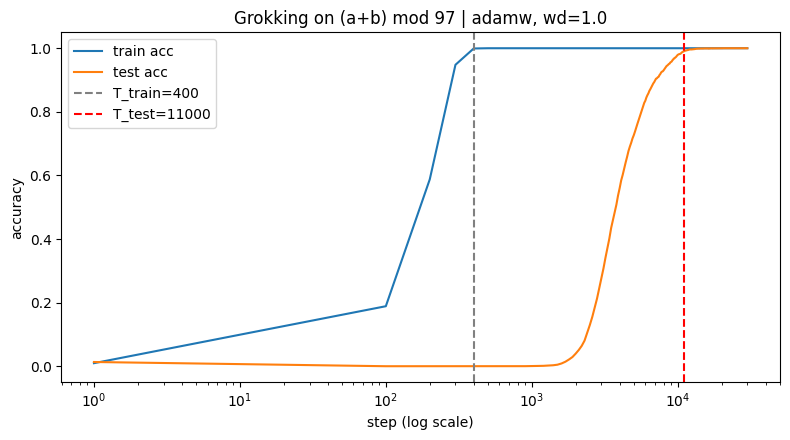

(400, 11000, 10600)

In [37]:
import matplotlib.pyplot as plt

def first_step_above(history, key, thresh=0.99):
    for s, v in zip(history["step"], history[key]):
        if v >= thresh:
            return s
    return None

def plot_run(history, title, save_path=None):
    t_train = first_step_above(history, "train_acc")
    t_test = first_step_above(history, "test_acc")
    delay = (t_test - t_train) if (t_train is not None and t_test is not None) else None
    print(f"T_train={t_train}  T_test={t_test}  delay={delay}")

    steps_ = [max(s, 1) for s in history["step"]]  # avoid log(0)
    plt.figure(figsize=(8, 4.5))
    plt.plot(steps_, history["train_acc"], label="train acc")
    plt.plot(steps_, history["test_acc"], label="test acc")
    if t_train:
        plt.axvline(max(t_train, 1), ls="--", c="gray", label=f"T_train={t_train}")
    if t_test:
        plt.axvline(t_test, ls="--", c="red", label=f"T_test={t_test}")
    plt.xscale("log")
    plt.xlabel("step (log scale)")
    plt.ylabel("accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return t_train, t_test, delay

plot_run(history,
         title=f"Grokking on (a+b) mod {P} | {OPTIMIZER}, wd={WEIGHT_DECAY}",
         save_path=f"results/{run_name}.png")